# Single-point diffusion model

This notebook models the spread of a pollutant released at $x = 0$ using the one-dimensional diffusion equation:

$$
\partial_{t}C(x,t) = D \partial_{xx}C(x,t)
$$

With the following boundary conditions

\begin{align}
    C(x,0) &= \delta(x) && \text{on }   \\
    C(\pm L, t) &= 0 && \text{on }  \\
    C_x(x,0) &= I(x) && \text{in }
\end{align}
Representing an instantaneous point release.

At the boundary points \(x=-100\) and \(x=100\), we use zero-flux conditions:

$$
\frac{\partial C}{\partial x}(-100,t) = 0,
\qquad
\frac{\partial C}{\partial x}(100,t) = 0.
$$

These conditions model a closed computational region and conserve total pollutant mass.

If the endpoints represent open edges where pollutant can leave, use absorbing conditions:

$$
C(-100,t) = C(100,t) = 0.
$$

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML


In [37]:
x_min, x_max = -100.0, 100.0
x0 = 0.0
source_strength = 1.0
D = 1.0
M = 500
T = 10.0

x = np.linspace(x_min, x_max, M + 1)
dx = x[1] - x[0]
dt = 0.45 * dx**2 / D
N = int(np.ceil(T / dt))
dt = T / N
t = np.linspace(0.0, T, N + 1)
C = D * dt / dx**2

if D <= 0.0:
    raise ValueError('D must be positive.')
if C > 0.5:
    raise ValueError(f'Unstable time step: D*dt/dx^2 = {C:.3f}')
print(f'dx={dx:.3e}, dt={dt:.3e}, N={N}, D*dt/dx^2={C:.3f}')

dx=4.000e-01, dt=7.194e-02, N=139, D*dt/dx^2=0.450


## Dirac delta initial condition

The delta function is represented on the grid by placing its mass at the grid point containing $x_0$. The factor $1/\Delta x$ ensures that the discrete total mass is the requested `source_strength`.

Initial mass = 1.000000


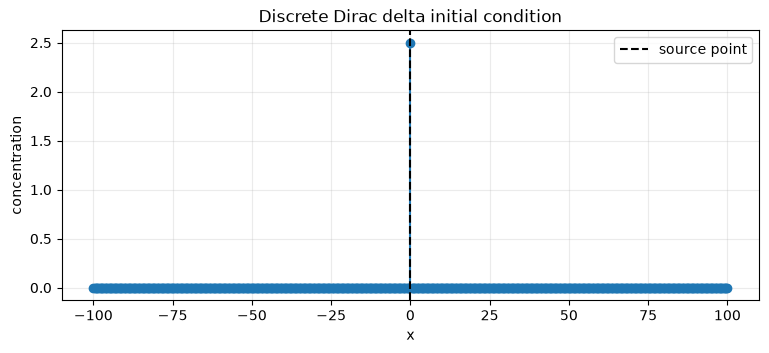

In [38]:
initial = np.zeros_like(x)
source_index = np.argmin(np.abs(x - x0))
initial[source_index] = source_strength / dx
initial_mass = np.sum(initial) * dx

if not np.isclose(initial_mass, source_strength):
    raise RuntimeError('The discrete Dirac delta has the wrong total mass.')
print(f'Initial mass = {initial_mass:.6f}')

plt.figure(figsize=(9, 3.5))
plt.stem(x, initial, basefmt=' ')
plt.axvline(x0, color='black', linestyle='--', label='source point')
plt.xlabel('x')
plt.ylabel('concentration')
plt.title('Discrete Dirac delta initial condition')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## Diffusion solution

Mirrored ghost points impose the zero-flux boundary conditions at both endpoints.

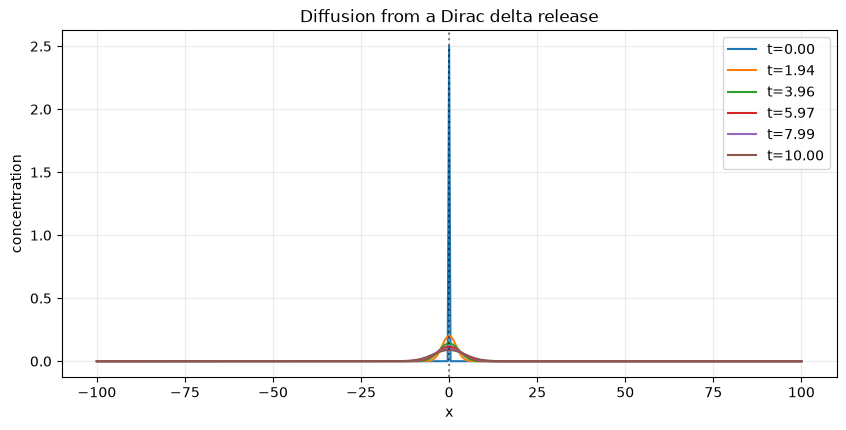

Relative mass change: 3.775e-15


In [39]:
solution = np.zeros((N + 1, M + 1))
solution[0] = initial

for n in range(N):
    current = solution[n]
    updated = current.copy()
    updated[1:-1] = current[1:-1] + C * (
        current[:-2] - 2.0 * current[1:-1] + current[2:]
    )
    updated[0] = current[0] + 2.0 * C * (current[1] - current[0])
    updated[-1] = current[-1] + 2.0 * C * (current[-2] - current[-1])
    solution[n + 1] = updated

if solution.min() < -1e-12:
    raise RuntimeError('Negative concentration detected; reduce the time step.')

indices = np.linspace(0, N, 6, dtype=int)
plt.figure(figsize=(10, 4.5))
for i in indices:
    plt.plot(x, solution[i], label=f't={t[i]:.2f}')
plt.axvline(x0, color='black', linestyle=':', alpha=0.5)
plt.xlabel('x')
plt.ylabel('concentration')
plt.title('Diffusion from a Dirac delta release')
plt.legend()
plt.grid(alpha=0.25)
plt.show()

integrate = np.trapezoid if hasattr(np, 'trapezoid') else np.trapz
mass = integrate(solution, x, axis=1)
print(f'Relative mass change: {(mass[-1] - mass[0]) / mass[0]:.3e}')

## Live concentration plot

The animation shows the Dirac delta release spreading through the domain. The zero-flux boundary conditions prevent pollutant from crossing either endpoint.


In [40]:
fig, ax = plt.subplots(figsize=(10, 4.5))
line, = ax.plot(x, solution[0], color='tab:blue', linewidth=2)
ax.axvline(x0, color='black', linestyle=':', alpha=0.6)
time_label = ax.text(0.02, 0.94, '', transform=ax.transAxes)
ax.set_xlim(x_min, x_max)
ax.set_ylim(0.0, 1.05 * solution.max())
ax.set_xlabel('x')
ax.set_ylabel('concentration')
ax.set_title('Diffusion from a Dirac delta release')
ax.grid(alpha=0.25)

def update(frame):
    line.set_ydata(solution[frame])
    time_label.set_text(f't = {t[frame]:.2f}')
    return line, time_label

animation = FuncAnimation(
    fig, update, frames=range(0, len(t), max(1, N // 200)),
    interval=40, blit=True, repeat=True
)
plt.close(fig)
HTML(animation.to_jshtml())
